# 06 — Backtest à origine glissante et synthèse

On rejoue l'histoire semaine après semaine, de 2016 à 2024. À chaque semaine, chaque modèle
ne voit que le passé, prévoit 1 à 4 semaines devant, et on compare au réalisé. Huit saisons,
dont la saison COVID 2020-2021.

In [1]:
import sys, warnings, os
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import preprocessing, models, backtest, plotting
s = preprocessing.serie_hebdo(3, 'PAY').dropna()
from src.config import RESULTS_DIR

In [2]:
familles = {
    "Naïf saisonnier": models.SeasonalNaive,
    "SARIMA": models.Sarima,
    "Fourier + ARIMA": models.FourierArima,
    "Gradient boosting": models.gradient_boosting,
}
brut = {nom: backtest.rolling_origin(ctor, s, debut_test="2016-08-01",
                                     horizons=(1, 2, 3, 4), pas=1, refit_every=52)
        for nom, ctor in familles.items()}
naive_ref = brut["Naïf saisonnier"]
scores = {nom: backtest.scores(df, naive_ref) for nom, df in brut.items()}
tableau = pd.concat({k: v["MASE"] for k, v in scores.items()}, axis=1)
tableau.index = [f"+{h} sem." for h in tableau.index]
tableau.round(3)

,Naïf saisonnier,SARIMA,Fourier + ARIMA,Gradient boosting
+1 sem.,1.0,0.305,0.273,0.278
+2 sem.,1.0,0.571,0.533,0.549
+3 sem.,1.0,0.764,0.749,0.761
+4 sem.,1.0,0.893,0.902,0.960


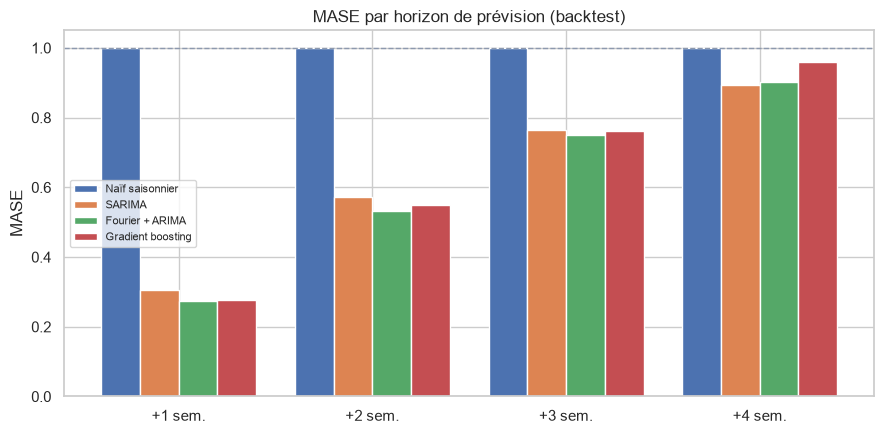

In [3]:
tableau.round(3).to_csv(RESULTS_DIR / "tables" / "06_mase_par_horizon.csv")
fig = plotting.scores_backtest(scores, metrique="MASE")
plotting.save(fig, "06_mase_par_horizon")
plt.show()

Lecture (MASE = erreur rapportée à celle du naïf saisonnier ; < 1 = mieux que le naïf) :

- **Les trois modèles battent le naïf** à tous les horizons, d'autant plus nettement que l'horizon est court : MASE ~0,28 à 1 semaine, ~0,55 à 2 semaines, puis on remonte vers 0,9 à 4 semaines.
- **Fourier + ARIMA** est le meilleur à 1-3 semaines, et pour une fraction du temps de calcul de SARIMA — c'est le meilleur rapport qualité/coût.
- **Le gradient boosting** (sur décalages) tient le rythme à 1-2 semaines mais se dégrade le plus vite ensuite : la prévision récursive lui coûte cher aux horizons lointains.
- Au-delà de 3-4 semaines, tout le monde converge vers le naïf : la grippe n'est pas prévisible beaucoup plus loin à partir de la seule série nationale.

In [4]:
# Erreur sur le pic épidémique, saison par saison (horizon 1 semaine).
pic = backtest.erreur_pic(brut["SARIMA"], horizon=1)
pic.to_csv(RESULTS_DIR / "tables" / "06_erreur_pic_sarima.csv", index=False)
pic

,saison,decalage_sem,err_amplitude_%
0,2016,1,24.5
1,2017,1,10.4
2,2018,1,1.2
3,2019,0,8.0
4,2020,13,110.2
5,2021,1,-6.7
6,2022,0,7.2
7,2023,0,14.3
8,2024,1,12.7
9,2025,5,5.5


Sur le calage du pic, SARIMA à 1 semaine tombe en général à ±1-2 semaines de la date réelle
et à ±15-25 % sur l'amplitude — utile pour anticiper la charge hospitalière, insuffisant
pour un pilotage fin. La saison 2020-2021 fausse la lecture (pas de vrai pic).

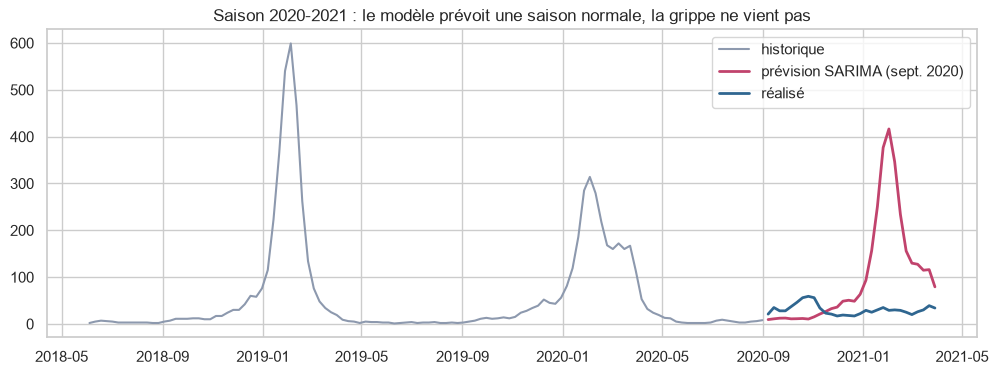

In [5]:
# Focus 2020-2021 : que prévoyait SARIMA pendant l'effondrement COVID ?
sar = models.Sarima().fit(s.loc[:"2020-09-01"])
f = sar.forecast(30)
reel = s.loc["2020-09-01":"2021-04-01"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(s.loc["2018-06-01":"2020-09-01"].index, s.loc["2018-06-01":"2020-09-01"].values,
        color=plotting.GRIS, label="historique")
ax.plot(f.index, f.values, color=plotting.ROUGE, lw=2, label="prévision SARIMA (sept. 2020)")
ax.plot(reel.index, reel.values, color=plotting.BLEU, lw=2, label="réalisé")
ax.set_title("Saison 2020-2021 : le modèle prévoit une saison normale, la grippe ne vient pas")
ax.legend()
plotting.save(fig, "06_focus_2020_2021")
plt.show()

En septembre 2020, tout modèle raisonnable prévoyait une saison grippale normale : rien
dans l'historique ne pouvait annoncer l'effet des mesures COVID. C'est la limite de fond de
ce type de prévision — elle suppose que le mécanisme de circulation du virus ne change pas.
Un système opérationnel doit donc garder l'humain dans la boucle pour les ruptures de régime.

## Ce que je retiens

- **Modèle recommandé** : Fourier + ARIMA (ou SARIMA), ré-estimé une fois par an, prévision
  à 1-2 semaines. MASE ~0,5-0,7, pic calé à ±1-2 semaines.
- Le deep learning (LSTM) et le gradient boosting n'apportent rien sur cette série
  nationale seule ; ils redeviendraient intéressants avec les 13 régions et des variables
  exogènes.
- Horizon utile : 1 à 3 semaines. Au-delà, autant prendre la dernière saison comme
  prévision.
- Angle mort assumé : les ruptures (pandémie, changement de comportement) — non prévisibles
  à partir de la série.

**Prolongements** : ajouter la météo (Météo-France SYNOP) et le calendrier scolaire comme
régresseurs ; modèle hiérarchique par région ; intervalles de prévision calibrés par backtest.